
## Assignment 7 — NLP-I



In [4]:
ROLL_NO = int(input("Enter roll number: "))
NAME = input("Enter name: ")

try:
    import nltk
except ImportError:
    import sys, subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "nltk"])
    import nltk

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"
print(f"Setup complete for {NAME} (Roll No: {ROLL_NO}).")


  Using cached nltk-3.10.3-py3-none-any.whl.metadata (3.2 kB)


  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)


  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
Using cached nltk-3.10.3-py3-none-any.whl (1.8 MB)
Using cached click-8.5.0-py3-none-any.whl (125 kB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [nltk]3/4 [nltk]



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip


Setup complete for Dhruv singla (Roll No: 1024170434).


### Dataset generator

In [5]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint


### Preprocessing pipeline

In [6]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}


In [7]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(f"Assigned Focus Tickets: {FOCUS}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)


Roll number: 1024170434   Name: Dhruv singla   Fingerprint: 9683FDFE   Tickets: 16

Assigned Focus Tickets: ['T06', 'T10']

Ticket_ID                                                                                  Ticket_Text
      T01                   I tried restarting the VPN before the assignment deadline. This is urgent.
      T02                                                        I need Windows 11 by 5.30 p.m. today.
      T03                                                                  My roll no. is 1023-03-021.
      T04    I keep getting logged out of the Python after resetting my password. It worked yesterday.
      T05                                         The projector is running slowly. Can you check this?
      T06                            The projector is showing an error. The same problem occurs again.
      T07                        E-mail failed to open after resetting my password. Please resolve it.
      T08                    I am unable to use the 

---

## Q1. Preprocessing pipeline

In [8]:
q1_rows = []
for idx, row in df.iterrows():
    p = process_ticket(row['Ticket_Text'])
    q1_rows.append({
        'Ticket_ID': row['Ticket_ID'],
        'Sentences': len(p['sentences']),
        'Tokens': len(p['tokens']),
        'Punctuation': len(p['punct']),
        'Stopwords': len(p['stops']),
        'Unique Tokens': len(set(p['tokens'])),
        'Final Tokens': len(p['final'])
    })

df_q1 = pd.DataFrame(q1_rows)

all_corpus_tokens = [t for text in df['Ticket_Text'] for t in process_ticket(text)['tokens']]
total_unique_tokens = len(set(all_corpus_tokens))

total_row = pd.DataFrame([{
    'Ticket_ID': 'TOTAL',
    'Sentences': df_q1['Sentences'].sum(),
    'Tokens': df_q1['Tokens'].sum(),
    'Punctuation': df_q1['Punctuation'].sum(),
    'Stopwords': df_q1['Stopwords'].sum(),
    'Unique Tokens': total_unique_tokens,
    'Final Tokens': df_q1['Final Tokens'].sum()
}])

df_q1_summary = pd.concat([df_q1, total_row], ignore_index=True)

print("="*80)
print("Q1 PREPROCESSING SUMMARY TABLE (WITH TOTAL ROW)")
print("="*80)
print(df_q1_summary.to_string(index=False))

focus_id = FOCUS[0]
focus_row = df[df['Ticket_ID'] == focus_id].iloc[0]
focus_proc = process_ticket(focus_row['Ticket_Text'])

print("\n" + "="*80)
print(f"DETAILED TOKEN BREAKDOWN FOR SELECTED TICKET: {focus_id}")
print("="*80)
print(f"Ticket Text:\n  \"{focus_row['Ticket_Text']}\"\n")
print(f"1. Sentences ({len(focus_proc['sentences'])}):\n  {focus_proc['sentences']}\n")
print(f"2. All Tokens ({len(focus_proc['tokens'])}):\n  {focus_proc['tokens']}\n")
print(f"3. Punctuation Tokens ({len(focus_proc['punct'])}):\n  {focus_proc['punct']}\n")
print(f"4. Stopwords ({len(focus_proc['stops'])}):\n  {focus_proc['stops']}\n")
print(f"5. Final Tokens ({len(focus_proc['final'])}):\n  {focus_proc['final']}")

focus_id2 = FOCUS[1]
focus_row2 = df[df['Ticket_ID'] == focus_id2].iloc[0]
focus_proc2 = process_ticket(focus_row2['Ticket_Text'])
print("\n" + "="*80)
print(f"DETAILED TOKEN BREAKDOWN FOR SECOND FOCUS TICKET: {focus_id2}")
print("="*80)
print(f"Ticket Text:\n  \"{focus_row2['Ticket_Text']}\"\n")
print(f"All Tokens: {focus_proc2['tokens']}")
print(f"Punctuation: {focus_proc2['punct']}")
print(f"Stopwords: {focus_proc2['stops']}")
print(f"Final Tokens: {focus_proc2['final']}")


Q1 PREPROCESSING SUMMARY TABLE (WITH TOTAL ROW)
Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique Tokens  Final Tokens
      T01          2      14            2          6             12             6
      T02          1       9            1          2              9             6
      T03          2       7            2          3              6             2
      T04          2      17            2          7             16             8
      T05          2      11            2          5             11             4
      T06          2      13            2          6             11             5
      T07          2      13            2          4             12             7
      T08          2      16            2          7             14             7
      T09          1      11            2          5              8             4
      T10          2      13            4          3             12             6
      T11          2      17            2         

Ans: In the dataset, the final tokens that are not standard standalone words are 's (found in tickets T09 and T10) and n't (found in ticket T16).

These come from word_tokenize which follows Penn Treebank conventions and splits contractions and possessives like couldn't into could and n't, and Dr. Rao's into Dr., Rao, and 's. While base stopwords like could and it are removed by the stopword list, the contracted fragments n't and 's are not present in NLTK's English stopword list. Also, is_punct only checks if every character is in string.punctuation. Because n't and 's contain letters, is_punct returns False, so they avoid both filters and end up in the final tokens list.

---

## Q2. Regular expressions

In [9]:
import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

pat_words_gt_5 = r'\b[A-Za-z]{6,}\b'
pat_numbers = r'\b\d+(?:[.,]\d+)+\b|\b\d+\b'
pat_cap_words = r'\b[A-Z][A-Za-z]*\b'
pat_vowel_words = r'\b[aeiouAEIOU][A-Za-z]*\b'

pat_email = r'[a-zA-Z0-9_.+-]+@[a-zA-Z0-9-]+\.[a-zA-Z0-9-.]+'
pat_url = r'https?://[^\s,;]+(?<![.,;])|www\.[^\s,;]+(?<![.,;])'
pat_phone = r'(?:\+91[\s-]?)?\d{5}[\s-]?\d{5}|\b\d{4}-\d{3}-\d{4}\b'

print("="*80)
print("PART A: EXTRACTION ON TEST_LINES")
print("="*80)
for i, line in enumerate(TEST_LINES, 1):
    print(f"\n[TEST LINE {i}]: {line}")
    print("  Words > 5 letters:           ", re.findall(pat_words_gt_5, line))
    print("  Numbers (decimals/versions): ", re.findall(pat_numbers, line))
    print("  Capitalized words:           ", re.findall(pat_cap_words, line))
    print("  Words starting with a vowel: ", re.findall(pat_vowel_words, line))

print("\n" + "="*80)
print("PART B: REPLACEMENT ON TEST_LINES")
print("="*80)
for i, line in enumerate(TEST_LINES, 1):
    cleaned = line
    cleaned = re.sub(pat_email, '<EMAIL>', cleaned)
    cleaned = re.sub(pat_url, '<URL>', cleaned)
    cleaned = re.sub(pat_phone, '<PHONE>', cleaned)
    print(f"\n[Original {i}]: {line}")
    print(f"[Replaced {i}]: {cleaned}")

print("\n" + "="*80)
print("PART C: EXTRACTION & REPLACEMENT ON RAW TICKETS DATASET")
print("="*80)
all_tickets_text = " ".join(df['Ticket_Text'])

raw_gt5 = re.findall(pat_words_gt_5, all_tickets_text)
raw_numbers = re.findall(pat_numbers, all_tickets_text)
raw_cap = re.findall(pat_cap_words, all_tickets_text)
raw_vowels = re.findall(pat_vowel_words, all_tickets_text)

print(f"Total words > 5 letters: {len(raw_gt5)} (Unique: {len(set(raw_gt5))})")
print(f"Sample words > 5 letters: {sorted(list(set(raw_gt5)))[:10]}")
print(f"\nTotal numbers matched: {len(raw_numbers)}")
print(f"Extracted numbers: {raw_numbers}")
print(f"\nTotal capitalized words: {len(raw_cap)} (Unique: {len(set(raw_cap))})")
print(f"Unique capitalized words: {sorted(list(set(raw_cap)))}")
print(f"\nTotal vowel-starting words: {len(raw_vowels)} (Unique: {len(set(raw_vowels))})")
print(f"Sample vowel-starting words: {sorted(list(set(raw_vowels)))[:10]}")

print("\n--- Sample Ticket Replacements ---")
for idx, row in df.head(5).iterrows():
    text = row['Ticket_Text']
    rep = re.sub(pat_email, '<EMAIL>', text)
    rep = re.sub(pat_url, '<URL>', rep)
    rep = re.sub(pat_phone, '<PHONE>', rep)
    print(f"{row['Ticket_ID']} Original: {text}")
    print(f"{row['Ticket_ID']} Replaced: {rep}\n")


PART A: EXTRACTION ON TEST_LINES

[TEST LINE 1]: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  Words > 5 letters:            ['helpdesk', 'thapar', 'thapar', 'thapar']
  Numbers (decimals/versions):  []
  Capitalized words:            ['Mail']
  Words starting with a vowel:  ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']

[TEST LINE 2]: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  Words > 5 letters:            ['Version']
  Numbers (decimals/versions):  ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
  Capitalized words:            ['Call', 'Version', 'Rs']
  Words starting with a vowel:  ['or', 'is']

[TEST LINE 3]: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
  Words > 5 letters:            []
  Numbers (decimals/versions):  ['5.30']
  Capitalized words:            [

Ans: Out of 42 capitalized word instances found in the tickets, 13 are capitalized only because they appear at the start of a sentence.

These words are The (4 times), It (3 times), Please (2 times), This (1 time), Can (1 time), My (1 time), and Is (1 time). The remaining capitalized words are either the pronoun I or domain-specific proper nouns and abbreviations like Python, Matlab, VPN, Wi-Fi, PC, Windows, and Dr. Rao which are always capitalized regardless of their position in a sentence.

---

## Q3. Custom tokenization

In [10]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

custom_pattern = r'''(?x)
    https?://[^\s,;]+(?<![.,;])|www\.[^\s,;]+(?<![.,;])
    | [a-zA-Z0-9_.+-]+@[a-zA-Z0-9-]+\.[a-zA-Z0-9-.]+
    | \+91[\s-]\d{5}[\s-]\d{5}|\d{4}-\d{3}-\d{4}
    | \d+(?:\.\d+)+
    | \d{1,3}(?:,\d{3})+
    | [A-Za-z0-9]+(?:-[A-Za-z0-9]+)+
    | [A-Za-z]+'(?:[A-Za-z]+)
    | [A-Za-z]+(?:\.[A-Za-z]+)+\.?
    | \w+
    | [^\s\w]
'''

custom_tokenizer = RegexpTokenizer(custom_pattern)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

print("="*80)
print("TOKENIZER COMPARISON ON TEST_LINES")
print("="*80)
for i, line in enumerate(TEST_LINES, 1):
    print(f"\n--- TEST LINE {i} ---")
    print(f"Input: {line}")
    m_tokens = my_tokenize(line)
    w_tokens = word_tokenize(line)
    print(f"my_tokenize ({len(m_tokens)} tokens):\n  {m_tokens}")
    print(f"word_tokenize ({len(w_tokens)} tokens):\n  {w_tokens}")

print("\n" + "="*80)
print("TOKENIZER COMPARISON ON GENERATED TICKETS")
print("="*80)
ticket_diffs = []
for idx, row in df.iterrows():
    tid = row['Ticket_ID']
    text = row['Ticket_Text']
    m_tok = my_tokenize(text)
    w_tok = word_tokenize(text)
    if m_tok != w_tok:
        ticket_diffs.append((tid, text, m_tok, w_tok))
        print(f"\nDiffering Ticket: {tid}")
        print(f"Text: \"{text}\"")
        print(f"  my_tokenize:   {m_tok}")
        print(f"  word_tokenize: {w_tok}")

print(f"\nSummary: {len(ticket_diffs)} out of {len(df)} tickets tokenized differently.")


TOKENIZER COMPARISON ON TEST_LINES

--- TEST LINE 1 ---
Input: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize (10 tokens):
  ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
word_tokenize (16 tokens):
  ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

--- TEST LINE 2 ---
Input: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize (18 tokens):
  ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
word_tokenize (20 tokens):
  ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5',

Ans: There are 3 tickets (T09, T10, and T16) that are tokenized differently by my_tokenize compared to word_tokenize in the dataset.

The three main differences between the two tokenizers are:
1. Contractions: my_tokenize keeps contractions like isn't, didn't, and couldn't as single tokens, while word_tokenize splits them into separate tokens like could and n't.
2. Email addresses and URLs: my_tokenize preserves complete email addresses and web links as single units, whereas word_tokenize breaks them apart at characters like @, :, and slashes.
3. Phone numbers: my_tokenize keeps formatted phone numbers with spaces or hyphens like +91 98765 43210 intact as one token, while word_tokenize splits them on whitespace into multiple pieces.

---

## Q4. Stemming and lemmatization

In [11]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

corpus_final_tokens = []
for text in df['Ticket_Text']:
    corpus_final_tokens.extend(process_ticket(text)['final'])
unique_final_tokens = sorted(list(set(corpus_final_tokens)))

regexp_stemmer = RegexpStemmer('ing$', min=4)

porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(treebank_tag):
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

tagged_tokens = nltk.pos_tag(unique_final_tokens)
pos_lookup = dict(tagged_tokens)

differing_rows = []
for word in unique_final_tokens:
    p_res = porter.stem(word)
    l_res = lancaster.stem(word)
    r_res = regexp_stemmer.stem(word)
    
    tb_tag = pos_lookup[word]
    wn_pos = get_wordnet_pos(tb_tag)
    wn_res = lemmatizer.lemmatize(word, pos=wn_pos)
    
    distinct_outputs = {p_res, l_res, r_res, wn_res}
    if len(distinct_outputs) > 1 or distinct_outputs != {word}:
        differing_rows.append({
            'Word': word,
            'POS Tag': tb_tag,
            'Porter': p_res,
            'Lancaster': l_res,
            'Regexp(ing)': r_res,
            'WordNet (POS)': wn_res
        })

df_q4_diff = pd.DataFrame(differing_rows)

print("="*80)
print(f"STEMMING & LEMMATIZATION COMPARISON TABLE ({len(df_q4_diff)} of {len(unique_final_tokens)} words differ)")
print("="*80)
print(df_q4_diff.to_string(index=False))


STEMMING & LEMMATIZATION COMPARISON TABLE (44 of 69 words differ)
       Word POS Tag    Porter Lancaster Regexp(ing) WordNet (POS)
    another      DT     anoth     anoth     another       another
 assignment      NN    assign    assign  assignment    assignment
     campus      NN     campu      camp      campus        campus
   computer      NN    comput    comput    computer      computer
  connected     VBN   connect   connect   connected       connect
    crashes      VB     crash     crash     crashes         crash
   deadline      JJ   deadlin   deadlin    deadline      deadline
      error      NN     error        er       error         error
     failed     VBD      fail      fail      failed          fail
       file      NN      file       fil        file          file
    getting     VBG       get       get        gett           get
     latest     JJS    latest    latest      latest          late
     logged     VBN       log       log      logged           log
     mobil

Ans: An example of over-stemming is Lancaster stemmer reducing student to stud and server to serv, where it strips too many letters and changes the actual meaning of the word. Another example is Porter stemmer reducing campus to campu because it incorrectly assumes the s at the end is a plural ending.

An example of under-stemming is the RegexpStemmer using the ing rule on words like connected, failed, logged, and worked, which leaves them completely unchanged because it only checks for ing. Also, Porter stemmer turns tried into tri instead of reducing it to the proper base word try.

---

## Q5. Corpus statistics

CORPUS STATISTICS: TOKENS, UNIQUE TOKENS, AND TTR
                     Corpus  Total Tokens  Unique Tokens  TTR (Lexical Diversity)
             S1: All tokens           217            102                   0.4700
    S2: Without punctuation           184             96                   0.5217
           S3: Final tokens           101             69                   0.6832
S4: S3 after Porter stemmer           101             66                   0.6535

TASK 1: TOP 10 WORDS IN S1 AND S3
Top 10 Words in S1 (All Tokens):
   1. .            (Count: 27)
   2. the          (Count: 17)
   3. i            (Count: 9)
   4. it           (Count: 8)
   5. is           (Count: 7)
   6. to           (Count: 6)
   7. another      (Count: 4)
   8. vpn          (Count: 3)
   9. my           (Count: 3)
  10. after        (Count: 3)

Top 10 Words in S3 (Final Tokens):
   1. another      (Count: 4)
   2. vpn          (Count: 3)
   3. server       (Count: 3)
   4. 's           (Count: 3)
   5. works   

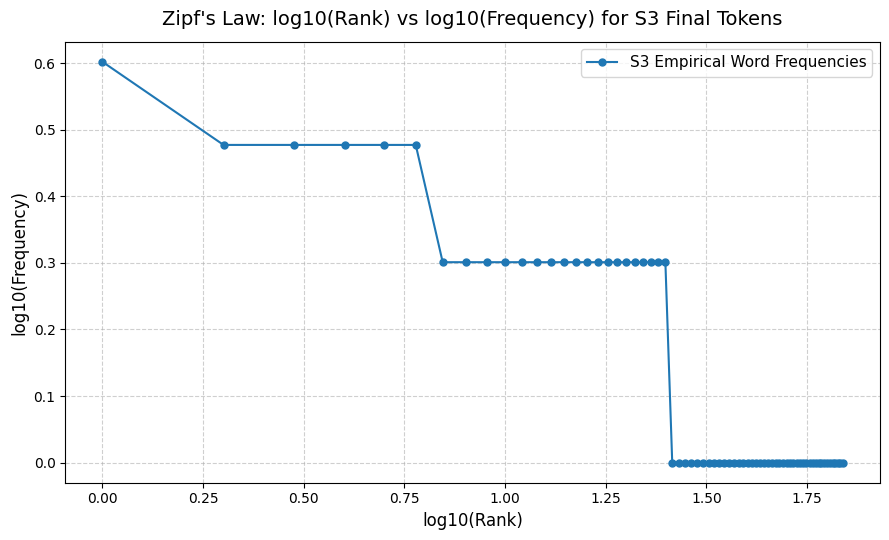


TASK 3: TOP 5 BIGRAMS IN S1 AND S3
Top 5 Bigrams in S1:
  1. . + i -> (Count: 7)
  2. . + it -> (Count: 5)
  3. the + vpn -> (Count: 3)
  4. . + the -> (Count: 3)
  5. it + works -> (Count: 3)

Top 5 Bigrams in S3:
  1. works + another -> (Count: 3)
  2. another + computer -> (Count: 3)
  3. resetting + password -> (Count: 2)
  4. showing + error -> (Count: 2)
  5. problem + occurs -> (Count: 2)


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from nltk.util import ngrams

S1 = [t for text in df['Ticket_Text'] for t in process_ticket(text)['tokens']]
S2 = [t for t in S1 if not is_punct(t)]
S3 = [t for text in df['Ticket_Text'] for t in process_ticket(text)['final']]

porter = PorterStemmer()
S4 = [porter.stem(t) for t in S3]

corpora_map = {
    'S1: All tokens': S1,
    'S2: Without punctuation': S2,
    'S3: Final tokens': S3,
    'S4: S3 after Porter stemmer': S4
}

stats_list = []
for name, token_list in corpora_map.items():
    tot = len(token_list)
    uniq = len(set(token_list))
    ttr = uniq / tot if tot > 0 else 0
    stats_list.append({
        'Corpus': name,
        'Total Tokens': tot,
        'Unique Tokens': uniq,
        'TTR (Lexical Diversity)': round(ttr, 4)
    })

df_stats = pd.DataFrame(stats_list)

print("="*80)
print("CORPUS STATISTICS: TOKENS, UNIQUE TOKENS, AND TTR")
print("="*80)
print(df_stats.to_string(index=False))

c1 = Counter(S1)
c3 = Counter(S3)

print("\n" + "="*80)
print("TASK 1: TOP 10 WORDS IN S1 AND S3")
print("="*80)
print("Top 10 Words in S1 (All Tokens):")
for rank, (w, count) in enumerate(c1.most_common(10), 1):
    print(f"  {rank:2d}. {w:<12} (Count: {count})")

print("\nTop 10 Words in S3 (Final Tokens):")
for rank, (w, count) in enumerate(c3.most_common(10), 1):
    print(f"  {rank:2d}. {w:<12} (Count: {count})")

freqs_s3 = sorted(list(c3.values()), reverse=True)
ranks_s3 = list(range(1, len(freqs_s3) + 1))

log_ranks = np.log10(ranks_s3)
log_freqs = np.log10(freqs_s3)

plt.figure(figsize=(9, 5.5))
plt.plot(log_ranks, log_freqs, marker='o', markersize=5, linestyle='-', color='#1f77b4', label='S3 Empirical Word Frequencies')
plt.xlabel('log10(Rank)', fontsize=12)
plt.ylabel('log10(Frequency)', fontsize=12)
plt.title("Zipf's Law: log10(Rank) vs log10(Frequency) for S3 Final Tokens", fontsize=14, pad=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

bg_s1 = Counter(ngrams(S1, 2))
bg_s3 = Counter(ngrams(S3, 2))

print("\n" + "="*80)
print("TASK 3: TOP 5 BIGRAMS IN S1 AND S3")
print("="*80)
print("Top 5 Bigrams in S1:")
for rank, (bg, count) in enumerate(bg_s1.most_common(5), 1):
    print(f"  {rank}. {bg[0]} + {bg[1]} -> (Count: {count})")

print("\nTop 5 Bigrams in S3:")
for rank, (bg, count) in enumerate(bg_s3.most_common(5), 1):
    print(f"  {rank}. {bg[0]} + {bg[1]} -> (Count: {count})")


Ans: TTR changes across the four stages because of how tokens and unique vocabulary are filtered:

Moving from S1 to S2, removing punctuation eliminates 33 tokens that only had 6 unique types. This drops the total token count significantly while barely reducing unique tokens, which increases the TTR from 0.4700 to 0.5217.

Moving from S2 to S3, removing common stopwords like the, is, to, and it removes 83 frequent functional words. The remaining tokens are mostly diverse content words, so TTR reaches its highest value at 0.6832.

Moving from S3 to S4, Porter stemming groups different grammatical forms of the same word together, such as works and worked into work. This reduces the number of unique words from 69 to 66 while keeping the total token count at 101, which slightly lowers the TTR to 0.6535.

---

## Q6. Interpretation

Ans (a): TTR measures lexical diversity. In S1, frequent punctuation marks pull the ratio down to 0.4700. In S2, stripping punctuation raises the ratio to 0.5217. In S3, removing common grammatical stopwords leaves mainly content words, raising the TTR to its highest point at 0.6832. In S4, Porter stemming reduces inflected forms like works and worked to work, decreasing unique words and bringing TTR down to 0.6535.

Ans (b): In ticket T16, word_tokenize splits couldn't into could and n't following Penn Treebank parsing rules. My tokenizer keeps couldn't as a single word token. Similarly, for an email like it.helpdesk@thapar.edu, word_tokenize splits it around the @ symbol, while my tokenizer keeps the entire email intact.

Ans (c): An undesirable result of stemming is over-stemming, such as Lancaster stemmer turning student into stud. This changes the word from an academic noun into an unrelated slang term, which would cause an IT support search system to match completely wrong records. Another issue is Porter stemmer turning tried into tri, creating an invalid non-word.

Ans (d): For the word tried (past tense verb), Porter stemmer produces tri, which is an invalid English word and distorts spelling. In contrast, WordNet lemmatizer uses part-of-speech information (verb) and a dictionary lookup to correctly return the valid dictionary base form try, preserving its true meaning.